# Political trust in Germany and France (ESS, minimal model)

A first, minimal look at trust in government institutions in Germany and France, loosely
inspired by Valgarðsson et al. (2025), *"A Crisis of Political Trust? Global Trends in
Institutional Trust from 1958 to 2019"* (`literature/a-crisis-of-political-trust-global-
trends-in-institutional-trust-from-1958-to-2019.pdf`).

That paper's central move is distinguishing trust in **representative** institutions
(parliament, politicians, parties) from trust in **implementing** institutions (legal system,
police) — the two move differently over time. We follow that split here with a minimal
Bayesian ordinal measurement model in PyMC, fit on a pre-filtered ESS subset covering only
Germany and France, rounds 1–11 (roughly 2002–2023).

**Out of scope for this pass:** regional resolution, and any connection to vote/party choice.
Both columns exist in the raw data but are unused here.

## Part 1 — Data overview

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../literature/ESS_Dataset/Datafile-subset.csv"

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]  # representative institutions
IMP_ITEMS = ["trstlgl", "trstplc"]  # implementing institutions
TRUST_ITEMS = REP_ITEMS + IMP_ITEMS

# Consistent country coloring across every plot in the notebook.
COUNTRY_COLORS = {"DE": "#1f77b4", "FR": "#ff7f0e"}

# The dataset itself carries no fieldwork year -- `proddate` is the data file's
# publication date, not the survey year (round 11 even shows "2026"). These are the
# documented ESS fieldwork start years (https://www.europeansocialsurvey.org), used
# here only as an approximate x-axis label. Round 10 fieldwork was delayed by COVID
# and ran into 2021-2022 in many countries; treat all years as indicative, not exact.
ROUND_YEARS = {
    1: 2002, 2: 2004, 3: 2006, 4: 2008, 5: 2010, 6: 2012,
    7: 2014, 8: 2016, 9: 2018, 10: 2020, 11: 2023,
}

df = pd.read_csv(DATA_PATH)
df = df[df["cntry"].isin(["DE", "FR"])].copy()
df["essround"] = df["essround"].astype(int)
df["year"] = df["essround"].map(ROUND_YEARS)
print(df.shape)
df[["cntry", "essround", "year"] + TRUST_ITEMS].head()

(57654, 288)


/var/folders/qj/4tk5ys5n6v753mb_m994csjh0000gn/T/ipykernel_31809/2392732329.py:24: DtypeWarning: Columns (0: region) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


,cntry,essround,year,trstprl,trstplt,trstprt,trstlgl,trstplc
0,DE,1,2002,0,0,NaN,6,9
1,DE,1,2002,7,4,NaN,7,10
2,DE,1,2002,4,4,NaN,9,6
3,DE,1,2002,6,2,NaN,8,8
4,DE,1,2002,3,1,NaN,4,4


In [2]:
# 77 = refusal, 88 = don't know, 99 = no answer, blank = not asked this round -> NaN
for col in TRUST_ITEMS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col].isin([77, 88, 99]), col] = np.nan

In [3]:
# Missingness per item, per country x round (flags e.g. trstprt unasked in round 1)
missing_pct = (
    df.groupby(["cntry", "essround"])[TRUST_ITEMS]
    .apply(lambda g: g.isna().mean() * 100)
    .round(1)
)
missing_pct

trstprl  trstplt  trstprt  trstlgl  trstplc
cntry essround                                             
DE    1             1.8      0.5    100.0      1.1      0.4
      2             2.6      0.8      1.5      1.6      0.5
      3             2.6      1.5      1.8      1.2      0.5
      4             1.8      0.8      1.5      1.3      0.3
      5             2.1      1.3      1.7      2.0      0.4
      6             1.4      0.6      1.2      1.2      0.3
      7             1.1      0.6      1.0      0.6      0.2
      8             1.4      0.7      1.3      0.7      0.3
      9             1.3      0.8      0.9      0.9      0.2
      10            1.9      1.6      2.0      1.7      1.4
      11            0.7      0.8      1.2      0.8      0.2
FR    1             1.9      0.3    100.0      0.4      0.3
      2             1.6      0.6      1.0      0.2      0.1
      3             2.2      0.6      1.1      0.3      0.3
      4             1.7      0.5      1.1      0.4      0.2
      5             1.3      0.5      0.5      0.2      0.1
      6             1.3      0.6      0.8      0.2      0.1
      7             1.7      0.4      0.7      0.2      0.1
      8             1.3      0.5      0.8      0.5      0.1
      9             3.0      2.1      2.4      0.9      0.7
      10            3.1      1.3      2.1      0.9      0.4
      11            2.5      1.0      1.4      0.4      0.2

In [4]:
def weighted_mean_se(g, col, wcol="pspwght"):
    """Weighted mean and its naive standard error (assumes iid sampling within the
    group -- no design effect / clustering correction, just a sanity-check band)."""
    sub = g[[col, wcol]].dropna()
    n = len(sub)
    if n == 0:
        return np.nan, np.nan, 0
    mean = np.average(sub[col], weights=sub[wcol])
    var = np.average((sub[col] - mean) ** 2, weights=sub[wcol])
    se = np.sqrt(var / n)
    return mean, se, n


raw_means = []
for (cntry, rnd), g in df.groupby(["cntry", "essround"]):
    row = {"cntry": cntry, "essround": rnd, "year": ROUND_YEARS[rnd]}
    for col in TRUST_ITEMS:
        row[f"{col}_unweighted"] = g[col].mean()
        mean, se, n = weighted_mean_se(g, col)
        row[f"{col}_weighted"] = mean
        row[f"{col}_se"] = se
        row[f"{col}_n"] = n
    raw_means.append(row)
raw_means = pd.DataFrame(raw_means).sort_values(["cntry", "essround"])
raw_means.head()

,cntry,essround,year,trstprl_unweighted,trstprl_weighted,trstprl_se,trstprl_n,trstplt_unweighted,trstplt_weighted,trstplt_se,...,trstprt_se,trstprt_n,trstlgl_unweighted,trstlgl_weighted,trstlgl_se,trstlgl_n,trstplc_unweighted,trstplc_weighted,trstplc_se,trstplc_n
0,DE,1,2002,4.348691,4.412448,0.043850,2865,3.424441,3.470772,0.039767,...,NaN,0,5.574498,5.715488,0.044532,2886,6.608531,6.769925,0.041647,2907
1,DE,2,2004,4.130590,4.171066,0.045179,2795,3.188335,3.232245,0.040328,...,0.039310,2828,5.431102,5.507764,0.045689,2823,6.385019,6.456954,0.042270,2857
2,DE,3,2006,4.094366,4.185891,0.044056,2840,3.181344,3.257843,0.041057,...,0.039803,2863,5.456597,5.611667,0.045674,2880,6.540662,6.623117,0.040893,2902
3,DE,4,2008,4.568678,4.598073,0.043885,2701,3.478197,3.523003,0.040449,...,0.039060,2710,5.641016,5.726413,0.046505,2716,6.731583,6.834072,0.042810,2742
4,DE,5,2010,4.180715,4.263184,0.042854,2966,3.294118,3.343534,0.040402,...,0.038913,2980,5.537193,5.650060,0.044828,2971,6.756211,6.876818,0.040340,3019


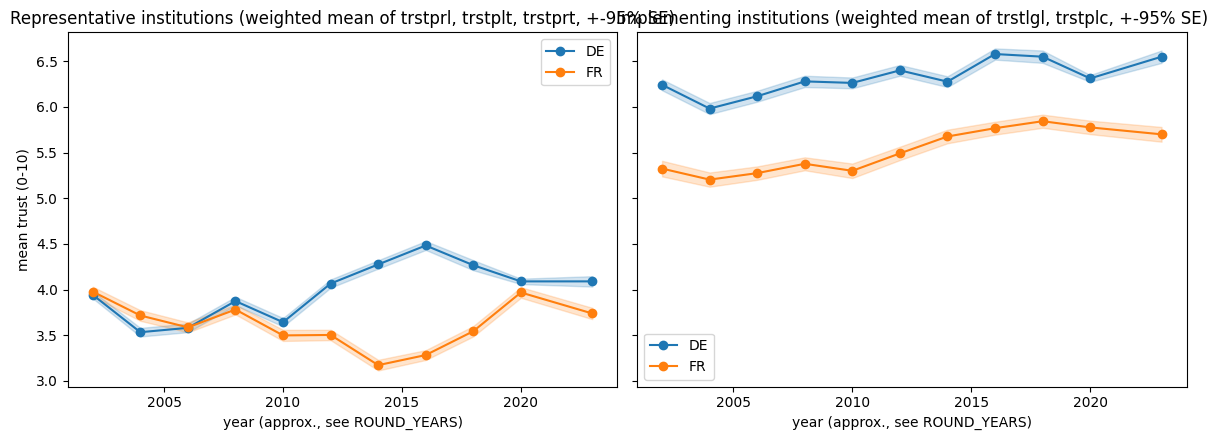

In [5]:
# Overview: average raw trust across the items in each dimension, per country, with a
# +-1.96*SE band (naive iid SE from the group sample size -- see weighted_mean_se above).
# Per-item detail (and the model's fit against each item) comes later, in Part 2.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, items, title in zip(axes, [REP_ITEMS, IMP_ITEMS], ["Representative", "Implementing"]):
    for cntry in ["DE", "FR"]:
        sub = raw_means[raw_means["cntry"] == cntry]
        mean_cols = [f"{item}_weighted" for item in items]
        se_cols = [f"{item}_se" for item in items]
        dim_mean = sub[mean_cols].mean(axis=1)
        # combine per-item SEs assuming independence: SE of the average of k items
        dim_se = np.sqrt((sub[se_cols] ** 2).sum(axis=1)) / len(items)
        ax.plot(sub["year"], dim_mean, "-o", color=COUNTRY_COLORS[cntry], label=cntry)
        ax.fill_between(
            sub["year"], dim_mean - 1.96 * dim_se, dim_mean + 1.96 * dim_se,
            color=COUNTRY_COLORS[cntry], alpha=0.2,
        )
    ax.set_title(f"{title} institutions (weighted mean of {', '.join(items)}, +-95% SE)")
    ax.set_xlabel("year (approx., see ROUND_YEARS)")
    ax.legend()
axes[0].set_ylabel("mean trust (0-10)")
fig.tight_layout()

### Analysis table

Drop respondents missing any of the 5 items in scope (this mainly removes round 1, where
`trstprt` wasn't asked), then build a single `country x round` group index for the model.

In [6]:
analysis = df.dropna(subset=TRUST_ITEMS).copy()
print(f"Rows before dropna: {len(df)}, after: {len(analysis)}")
print(analysis.groupby("cntry").size())

for col in TRUST_ITEMS:
    analysis[col] = analysis[col].astype(int)

cntry_round = pd.Series(list(zip(analysis["cntry"], analysis["essround"])), index=analysis.index)
analysis["group"], group_labels = pd.factorize(cntry_round, sort=True)
group_labels = pd.MultiIndex.from_tuples(group_labels, names=["cntry", "essround"])
n_groups = len(group_labels)
country_of_group = (group_labels.get_level_values("cntry") == "FR").astype(int)
# country_of_group: 0 = DE, 1 = FR
print(f"n_groups={n_groups}")
group_labels[:5]

Rows before dropna: 57654, after: 51535
cntry
DE    32782
FR    18753
dtype: int64
n_groups=20


MultiIndex([('DE', 2),
            ('DE', 3),
            ('DE', 4),
            ('DE', 5),
            ('DE', 6)],
           names=['cntry', 'essround'])

## Part 2 — Minimal PyMC model

Two respondent-level latent trust dimensions (`trust_rep`, `trust_imp`), each measured by an
ordinal graded-response model, with a hierarchical mean per `(country, round)` cell.

**Deviations from a naive single-factor / shared-cutpoints model, and why:**
- *Two dimensions, not one.* Collapsing all 5 items into one latent trust score would erase
  the paper's central finding that representative and implementing trust move differently.
- *Item-specific cutpoints.* Sharing one cutpoints vector across items (as in a single-factor
  draft) implicitly assumes parliament/politicians/parties/police/legal-system all have the
  same response base rate — empirically false (trust in police runs much higher than trust in
  politicians). Each item gets its own ordered cutpoints here.
- *Scale identification.* `trust_dim ~ Normal(mu_group, 1)` fixes the latent scale (sd=1); the
  weakly-informative prior centering cutpoints on `anchor = np.arange(10) - 4.5` resolves the
  residual location non-identifiability between the group means and the cutpoints. No
  reference-country constraint (e.g. `alpha[0] = 0`) is needed on top of that.
- *Known simplification:* `trust_rep` and `trust_imp` are modeled as independent latents —
  there is no cross-dimension correlation term. In reality the two are likely correlated at
  the respondent level; that's deferred to a later iteration, not an oversight.
- *Country × round, not a full dynamic model.* The paper fits a dynamic (random-walk) latent
  trait over time. Here, a hierarchical mean per `(country, round)` cell (partially pooled
  toward each country's overall level) is the minimal stand-in — it gives a trend per country
  without building the smoothing/state-space machinery.

In [7]:
import pymc as pm
import arviz as az

# Runtime tiers. Cost scales roughly with n_resp x (draws+tune), since every NUTS
# gradient step touches all ~2 x n_resp respondent-level latents (trust_rep, trust_imp).
# The model only has 20 country x round groups to estimate, so a few thousand
# respondents per country is already enough to pin those means down tightly -- the
# "full" tier mostly sharpens individual-respondent latents nobody is looking at.
#   debug:  ~10s   -- does the model run at all
#   medium: ~1 min -- good enough to sanity-check trends and iterate on model structure
#   full:   ~90 min on this machine -- final confirmatory run only
SAMPLE_SIZE = "medium"  # "debug" | "medium" | "full"

N_PER_COUNTRY = {"debug": 400, "medium": 2000, "full": None}[SAMPLE_SIZE]

if N_PER_COUNTRY is None:
    model_df = analysis.reset_index(drop=True)
else:
    model_df = (
        analysis.groupby("cntry", group_keys=False)
        .apply(lambda g: g.sample(min(N_PER_COUNTRY, len(g)), random_state=0))
        .reset_index(drop=True)
    )

y_rep = model_df[REP_ITEMS].to_numpy()
y_imp = model_df[IMP_ITEMS].to_numpy()
group_idx = model_df["group"].to_numpy()
n_resp = len(model_df)
print(f"n_resp={n_resp}, n_groups used={len(np.unique(group_idx))}")

n_resp=4000, n_groups used=20


In [8]:
anchor = np.arange(10) - 4.5
n_countries = 2

draws, tune, chains = {
    "debug": (300, 300, 2),
    "medium": (1000, 1000, 4),
    "full": (1000, 1000, 4),
}[SAMPLE_SIZE]

with pm.Model() as model:
    # --- structural part: hierarchical mean per country x round, per dimension ---
    alpha_rep = pm.Normal("alpha_rep", 0, 1, shape=n_countries)
    alpha_imp = pm.Normal("alpha_imp", 0, 1, shape=n_countries)

    sigma_round_rep = pm.HalfNormal("sigma_round_rep", 0.5)
    sigma_round_imp = pm.HalfNormal("sigma_round_imp", 0.5)

    z_rep = pm.Normal("z_rep", 0, 1, shape=n_groups)
    z_imp = pm.Normal("z_imp", 0, 1, shape=n_groups)
    mu_rep_group = pm.Deterministic(
        "mu_rep_group", alpha_rep[country_of_group] + z_rep * sigma_round_rep
    )
    mu_imp_group = pm.Deterministic(
        "mu_imp_group", alpha_imp[country_of_group] + z_imp * sigma_round_imp
    )

    # --- respondent-level latent trust ---
    trust_rep = pm.Normal("trust_rep", mu_rep_group[group_idx], 1, shape=n_resp)
    trust_imp = pm.Normal("trust_imp", mu_imp_group[group_idx], 1, shape=n_resp)

    # --- measurement part: item-specific cutpoints ---
    cut_rep = pm.Normal(
        "cut_rep",
        mu=anchor,
        sigma=1,
        shape=(len(REP_ITEMS), 10),
        transform=pm.distributions.transforms.ordered,
        initval=np.tile(anchor, (len(REP_ITEMS), 1)),
    )
    cut_imp = pm.Normal(
        "cut_imp",
        mu=anchor,
        sigma=1,
        shape=(len(IMP_ITEMS), 10),
        transform=pm.distributions.transforms.ordered,
        initval=np.tile(anchor, (len(IMP_ITEMS), 1)),
    )

    for j, name in enumerate(REP_ITEMS):
        pm.OrderedLogistic(name, eta=trust_rep, cutpoints=cut_rep[j], observed=y_rep[:, j])
    for j, name in enumerate(IMP_ITEMS):
        pm.OrderedLogistic(name, eta=trust_imp, cutpoints=cut_imp[j], observed=y_imp[:, j])

    idata = pm.sample(draws, tune=tune, chains=chains, cores=chains, target_accept=0.8, nuts_sampler="nutpie")

NUTS[nutpie]: [alpha_rep, alpha_imp, sigma_round_rep, sigma_round_imp, z_rep, z_imp, trust_rep, trust_imp, cut_rep, cut_imp]


Output()

## Diagnostics

In [9]:
az.summary(
    idata,
    var_names=["alpha_rep", "alpha_imp", "sigma_round_rep", "sigma_round_imp"],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha_rep[0],-1,0.22,-1.4,-0.71,14,33,1.21,0.058,0.014
alpha_rep[1],-1.51,0.23,-1.9,-1.2,20,72,1.13,0.05,0.013
alpha_imp[0],1.02,0.21,0.68,1.4,68,108,1.06,0.026,0.012
alpha_imp[1],0.26,0.2,-0.064,0.58,71,149,1.04,0.024,0.011
sigma_round_rep,0.391,0.072,0.29,0.52,870,1270,1.01,0.0025,0.0018
sigma_round_imp,0.333,0.068,0.24,0.45,879,1339,1.01,0.0023,0.0018


In [10]:
n_divergent = int(idata.sample_stats["diverging"].sum())
print(f"divergences: {n_divergent}")

divergences: 0


### Posterior country x round trust vs. the raw weighted means

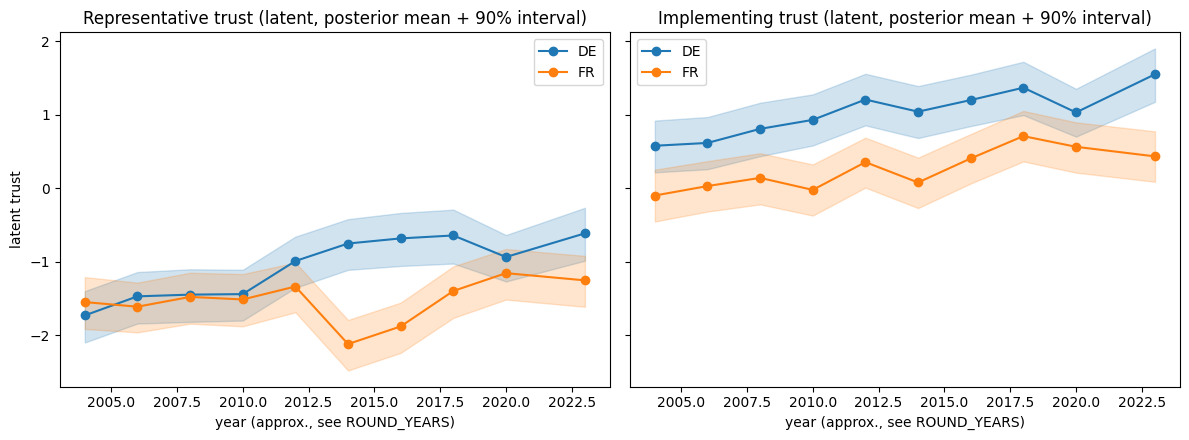

In [11]:
mu_rep_summary = az.summary(idata, var_names=["mu_rep_group"], ci_prob=0.9)
mu_imp_summary = az.summary(idata, var_names=["mu_imp_group"], ci_prob=0.9)

post = group_labels.to_frame(index=False)
post["year"] = post["essround"].map(ROUND_YEARS)
post["mu_rep"] = mu_rep_summary["mean"].to_numpy()
post["mu_rep_lo"] = mu_rep_summary["eti90_lb"].to_numpy()
post["mu_rep_hi"] = mu_rep_summary["eti90_ub"].to_numpy()
post["mu_imp"] = mu_imp_summary["mean"].to_numpy()
post["mu_imp_lo"] = mu_imp_summary["eti90_lb"].to_numpy()
post["mu_imp_hi"] = mu_imp_summary["eti90_ub"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, dim, title in zip(axes, ["rep", "imp"], ["Representative", "Implementing"]):
    for cntry in ["DE", "FR"]:
        sub = post[post["cntry"] == cntry].sort_values("year")
        ax.plot(sub["year"], sub[f"mu_{dim}"], "-o", color=COUNTRY_COLORS[cntry], label=cntry)
        ax.fill_between(
            sub["year"], sub[f"mu_{dim}_lo"], sub[f"mu_{dim}_hi"],
            color=COUNTRY_COLORS[cntry], alpha=0.2,
        )
    ax.set_title(f"{title} trust (latent, posterior mean + 90% interval)")
    ax.set_xlabel("year (approx., see ROUND_YEARS)")
    ax.legend()
axes[0].set_ylabel("latent trust")
fig.tight_layout()

### Model fit vs. raw data, per item

The latent trust plot above shows the *structural* part of the model. This checks the
*measurement* part: turn each item's posterior mean cutpoints and its dimension's posterior
mean group latent into a predicted average item score (`E[Y] = sum_k k * P(Y=k)`, using the
ordered-logistic category probabilities), and compare it to the raw weighted mean actually
observed for that item. If the item-specific cutpoints are doing their job, the dashed
"model fit" line should track the solid "raw data" line closely for every item, including
`trstplc` (police), which sits on a very different part of the 0-10 scale than `trstplt`
(politicians).

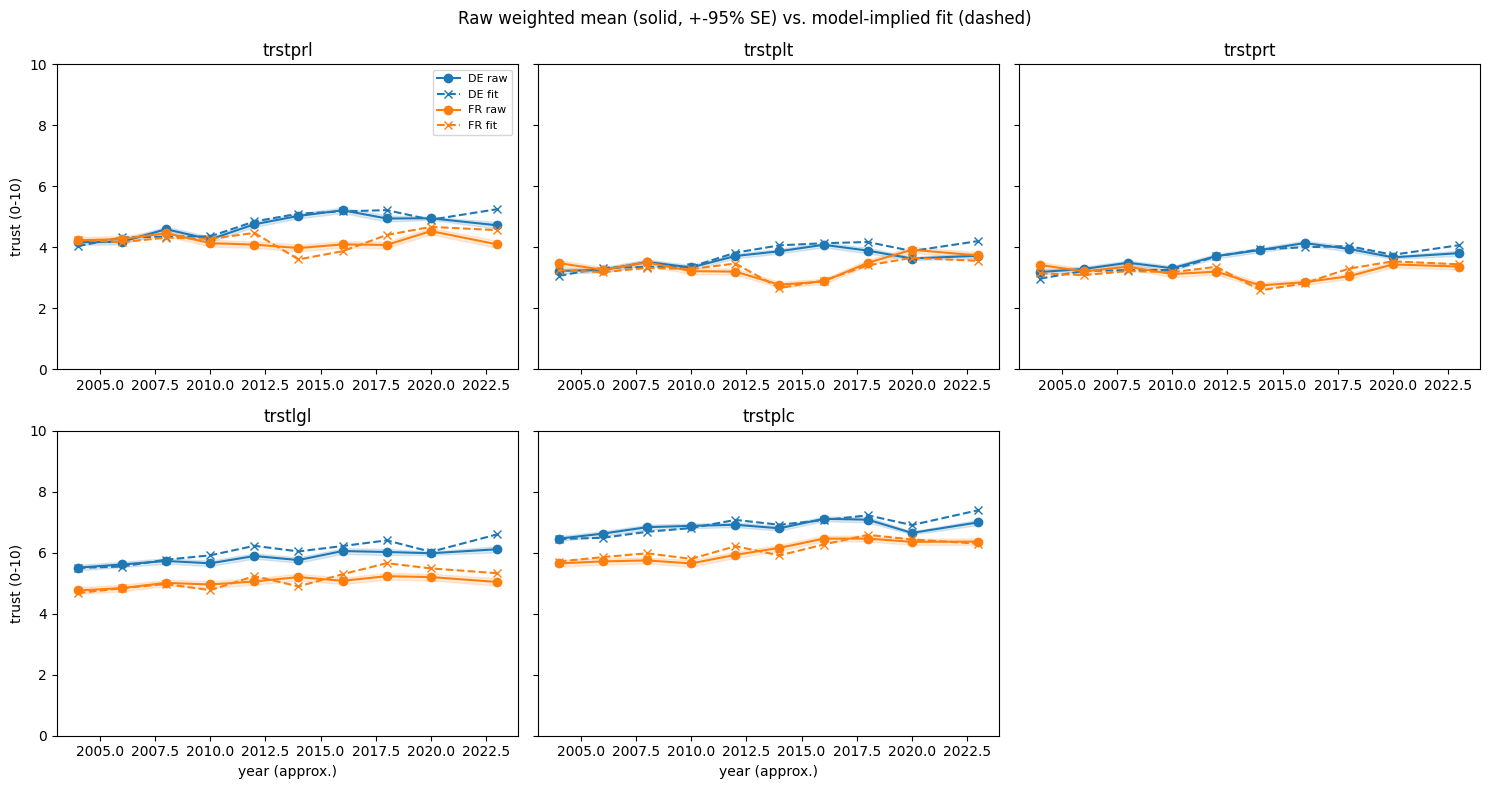

In [12]:
def expected_ordinal_score(eta, cutpoints):
    """E[Y] for an ordered-logistic item with 11 categories (0..10) and 10 cutpoints.

    eta: array (G,) of latent locations. cutpoints: array (10,) for one item.
    Returns array (G,) of predicted average scores.
    """
    eta = np.asarray(eta)[:, None]  # (G, 1)
    cps = np.asarray(cutpoints)[None, :]  # (1, 10)
    cdf_le = 1 / (1 + np.exp(-(cps - eta)))  # P(Y<=k), k=0..9 -> (G, 10)
    cdf = np.concatenate([cdf_le, np.ones((eta.shape[0], 1))], axis=1)  # P(Y<=10)=1 -> (G, 11)
    cdf_prev = np.concatenate([np.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    probs = cdf - cdf_prev  # P(Y=k), k=0..10 -> (G, 11)
    return probs @ np.arange(11)


mu_rep_mean = idata.posterior["mu_rep_group"].mean(("chain", "draw")).to_numpy()
mu_imp_mean = idata.posterior["mu_imp_group"].mean(("chain", "draw")).to_numpy()
cut_rep_mean = idata.posterior["cut_rep"].mean(("chain", "draw")).to_numpy()
cut_imp_mean = idata.posterior["cut_imp"].mean(("chain", "draw")).to_numpy()

pred = group_labels.to_frame(index=False)
pred["year"] = pred["essround"].map(ROUND_YEARS)
for j, item in enumerate(REP_ITEMS):
    pred[f"{item}_pred"] = expected_ordinal_score(mu_rep_mean, cut_rep_mean[j])
for j, item in enumerate(IMP_ITEMS):
    pred[f"{item}_pred"] = expected_ordinal_score(mu_imp_mean, cut_imp_mean[j])

fit_check = raw_means.merge(pred, on=["cntry", "essround", "year"])

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
axes = axes.ravel()
for ax, item in zip(axes, TRUST_ITEMS):
    for cntry in ["DE", "FR"]:
        sub = fit_check[fit_check["cntry"] == cntry].sort_values("year")
        color = COUNTRY_COLORS[cntry]
        ax.plot(sub["year"], sub[f"{item}_weighted"], "-o", color=color, label=f"{cntry} raw")
        ax.fill_between(
            sub["year"], sub[f"{item}_weighted"] - 1.96 * sub[f"{item}_se"],
            sub[f"{item}_weighted"] + 1.96 * sub[f"{item}_se"], color=color, alpha=0.15,
        )
        ax.plot(sub["year"], sub[f"{item}_pred"], "--x", color=color, label=f"{cntry} fit")
    ax.set_title(item)
    ax.set_ylim(0, 10)
axes[5].axis("off")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("trust (0-10)")
axes[3].set_ylabel("trust (0-10)")
for ax in axes[3:5]:
    ax.set_xlabel("year (approx.)")
fig.suptitle("Raw weighted mean (solid, +-95% SE) vs. model-implied fit (dashed)")
fig.tight_layout()

### Interpretation

*(Fill in once the full-data run completes.)* Compare the direction of the DE and FR trends
for representative vs. implementing trust against the paper's global finding — declining
trust in representative institutions, stable-or-rising trust in implementing institutions.
Note explicitly where this 2-country, 5-item, non-dynamic model agrees or disagrees, without
overclaiming: it has no regional resolution, no vote linkage, and pools rounds toward a
country mean rather than smoothing a proper time series.